# Multilingual Retrieval Fairness
### English · Hindi · Malayalam | Mini-project evaluation notebook

**Research question:** How does retrieval quality differ across English, Hindi and Malayalam, and can a lightweight hybrid retriever reduce the gap?

This notebook implements a compact, reproducible study:
1. Load the parallel Belebele benchmark.
2. Compare two compact multilingual embedding models and BM25.
3. Evaluate same-language (mono) and Hindi/Malayalam-to-English (cross) retrieval.
4. Apply reciprocal-rank-fusion (RRF) hybrid retrieval.
5. Measure recall, MRR, language gaps, latency and model footprint.
6. Support a small human answer-quality assessment using retrieved passages.

**Important:** This is a retrieval benchmark using Belebele questions and their associated passages. It is not a deployed public-services assistant. Answer quality is assessed separately through a small human-review sample; do not describe retrieval recall as answer accuracy.

## 0. Environment and reproducibility

Run this notebook in Google Colab or locally with Python 3.10+. A GPU is helpful but not mandatory for the small models.

If you already installed the packages in your project virtual environment, skip the install cell.

In [1]:
%pip -q install "datasets>=2.19" "sentence-transformers>=3.0,<6" "rank-bm25>=0.2.2" pandas numpy matplotlib seaborn tqdm

In [2]:
import os, re, json, time, random, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd()
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("Python:", platform.python_version())
print("Working directory:", ROOT)

Python: 3.13.16
Working directory: /content


## 1. Configuration

The two embedding models are intentionally compact:
- `intfloat/multilingual-e5-small`
- `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`

BM25 is the sparse lexical baseline. The hybrid system fuses BM25 and E5 rankings using reciprocal rank fusion.

For a quick smoke test, set `MAX_ITEMS` to 60. For the reported experiment, use the full aligned test set and record the final count.

In [3]:
LANG_CONFIG = {
    "en": {"config": "eng_Latn", "label": "English"},
    "hi": {"config": "hin_Deva", "label": "Hindi"},
    "ml": {"config": "mal_Mlym", "label": "Malayalam"},
}

MODEL_IDS = {
    "e5-small": "intfloat/multilingual-e5-small",
    "multilingual-minilm": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
}

MAX_ITEMS = None   # set to 60 for a quick smoke test; None means all aligned test rows
BATCH_SIZE = 32
TOP_K = (1, 5, 10)

## 2. Load and align the parallel Belebele data

Each benchmark row supplies a question and its associated passage. The passage is treated as that query's relevant document. We align rows using the benchmark's question identifier where possible and verify the parallel structure before evaluation.

If the dataset schema changes or a language configuration is unavailable, stop and inspect the dataset rather than silently assuming the rows are aligned.

In [4]:
def load_language(config_name):
    ds = load_dataset("facebook/belebele", config_name, split="test")
    df = ds.to_pandas()
    return df

raw = {code: load_language(info["config"]) for code, info in LANG_CONFIG.items()}
for lang, df in raw.items():
    print(lang, df.shape, list(df.columns))

README.md:   0%|          | 0.00/25.5k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/836k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

hin_Deva.jsonl:   0%|          | 0.00/3.12M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

mal_Mlym.jsonl:   0%|          | 0.00/3.83M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

en (900, 11) ['link', 'question_number', 'flores_passage', 'question', 'mc_answer1', 'mc_answer2', 'mc_answer3', 'mc_answer4', 'correct_answer_num', 'dialect', 'ds']
hi (900, 11) ['link', 'question_number', 'flores_passage', 'question', 'mc_answer1', 'mc_answer2', 'mc_answer3', 'mc_answer4', 'correct_answer_num', 'dialect', 'ds']
ml (900, 11) ['link', 'question_number', 'flores_passage', 'question', 'mc_answer1', 'mc_answer2', 'mc_answer3', 'mc_answer4', 'correct_answer_num', 'dialect', 'ds']


In [5]:
def find_id_column(df):
    for candidate in ["question_number", "link"]:
        if candidate in df.columns:
            return candidate
    return None

id_cols = {lang: find_id_column(df) for lang, df in raw.items()}
print("Alignment identifiers:", id_cols)

# The official configurations are expected to preserve parallel row order.
# If a common identifier exists in all three, sort and align by it.
common_id = id_cols["en"] if len(set(id_cols.values())) == 1 else None
if common_id:
    for lang in raw:
        raw[lang] = raw[lang].sort_values(common_id).reset_index(drop=True)

n = min(len(df) for df in raw.values())
if len({len(df) for df in raw.values()}) != 1:
    raise ValueError("Language splits have different row counts. Inspect and align by a verified shared ID.")

# Basic parallelism check. The passage content differs by language, but row identity/order should match.
# If a shared ID is present, verify it; otherwise preserve the dataset's published row order.
if common_id:
    base_ids = raw["en"][common_id].astype(str).tolist()
    for lang in ["hi", "ml"]:
        if raw[lang][common_id].astype(str).tolist() != base_ids:
            raise ValueError(f"Parallel IDs do not align for {lang}.")

if MAX_ITEMS is not None:
    raw = {lang: df.iloc[:MAX_ITEMS].reset_index(drop=True) for lang, df in raw.items()}
    n = MAX_ITEMS

print("Aligned benchmark rows:", n)

Alignment identifiers: {'en': 'question_number', 'hi': 'question_number', 'ml': 'question_number'}
Aligned benchmark rows: 900


### 2.1 Normalize fields and inspect one example

Belebele commonly uses `passage`, `question`, `mc_answer1`–`mc_answer4`, and `correct_answer_num`. This cell checks for the expected columns explicitly.

In [8]:
REQUIRED = ["passage", "question", "mc_answer1", "mc_answer2", "mc_answer3", "mc_answer4", "correct_answer_num"]

for lang, df in raw.items():
    if "passage" not in df.columns and "flores_passage" in df.columns:
        df = df.rename(columns={"flores_passage": "passage"})
        raw[lang] = df
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f"{lang} is missing expected columns: {missing}")

for lang in raw:
    raw[lang] = raw[lang].reset_index(drop=True)
    raw[lang]["passage"] = raw[lang]["passage"].fillna("").astype(str)
    raw[lang]["question"] = raw[lang]["question"].fillna("").astype(str)

display(pd.DataFrame({
    "language": list(raw.keys()),
    "rows": [len(raw[k]) for k in raw],
    "example_question": [raw[k].loc[0, "question"][:160] for k in raw],
}))

,language,rows,example_question
0,en,900,Which of the following aspects of the Catholic...
1,hi,900,"गद्यांश के अनुसार, पेरिस के लोगों को आपके लिए ..."
2,ml,900,ഇവയിൽ കത്തോലിക്കാ സഭയുടെ ഏത് വശങ്ങളാണ് വിചാരണയ...


### 2.2 Build unique passage collections
Belebele repeats the same passage across multiple questions. We index each unique passage once and map every question to its relevant passage. We also verify that the repeated-passage grouping is parallel across the three language configurations.

In [11]:
import re

def norm(s):
    return re.sub(r"\s+", " ", s).strip()

# Align rows across languages
for lang in raw:
    df = raw[lang]
    if "link" in df.columns and "question_number" in df.columns:
        df = df.sort_values(["link", "question_number"])
    raw[lang] = df.reset_index(drop=True)

def build_unique_corpus(df):
    docs, lookup, row_to_doc = [], {}, []
    # Prefer the cross-language passage id; fall back to normalized text
    keys = df["link"].tolist() if "link" in df.columns else [norm(p) for p in df["passage"]]
    for key, passage in zip(keys, df["passage"].tolist()):
        if key not in lookup:
            lookup[key] = len(docs)
            docs.append(passage)
        row_to_doc.append(lookup[key])
    return docs, row_to_doc

corpora, gold_indices = {}, {}
for lang, df in raw.items():
    corpora[lang], gold_indices[lang] = build_unique_corpus(df)

def grouping_pattern(indices):
    seen, pattern = {}, []
    for value in indices:
        if value not in seen:
            seen[value] = len(seen)
        pattern.append(seen[value])
    return pattern

patterns = {lang: grouping_pattern(gold_indices[lang]) for lang in raw}
if not (patterns["en"] == patterns["hi"] == patterns["ml"]):
    raise ValueError("Repeated-passage grouping is not parallel across languages. Inspect alignment before cross-language evaluation.")

print("Unique passages:", {lang: len(corpora[lang]) for lang in corpora})
print("Questions per language:", {lang: len(raw[lang]) for lang in raw})

Unique passages: {'en': 488, 'hi': 488, 'ml': 488}
Questions per language: {'en': 900, 'hi': 900, 'ml': 900}


## 3. Retrieval evaluation functions

For each language, all passages in that language form the candidate document collection. Each query maps to the unique passage that contains it. In cross-language evaluation, the gold index is taken from the target document language using the same aligned question row.

Metrics:
- **Recall@k:** whether the gold passage appears in the top k.
- **MRR:** reciprocal rank of the gold passage.
- **Language gap:** English score minus Hindi or Malayalam score, computed within the same evaluation condition and retrieval system.

The benchmark has one designated relevant passage per query. This is a benchmark convention, not a claim that no other passage could be relevant in a real service.

In [12]:
def recall_at_k(rankings, gold, k):
    return np.mean([int(g in row[:k]) for row, g in zip(rankings, gold)])

def mean_reciprocal_rank(rankings, gold):
    vals = []
    for row, g in zip(rankings, gold):
        hits = np.where(np.asarray(row) == g)[0]
        vals.append(1.0 / (int(hits[0]) + 1) if len(hits) else 0.0)
    return float(np.mean(vals))

def ranking_from_scores(scores):
    return np.argsort(-scores, axis=1)

def evaluate_rankings(rankings, gold, system, query_lang, doc_lang, condition, elapsed_s):
    row = {
        "system": system, "query_lang": query_lang, "doc_lang": doc_lang,
        "condition": condition, "n_queries": len(gold),
        "recall@1": recall_at_k(rankings, gold, 1),
        "recall@5": recall_at_k(rankings, gold, 5),
        "recall@10": recall_at_k(rankings, gold, 10),
        "mrr": mean_reciprocal_rank(rankings, gold),
        "latency_ms_per_query": elapsed_s * 1000 / max(1, len(gold)),
    }
    return row

def tokenize(text):
    # Unicode-aware tokenization. Retains words from Latin and Indic scripts.
    return re.findall(r"\w+", str(text).lower(), flags=re.UNICODE)

def bm25_scores(queries, docs):
    tokenized_docs = [tokenize(d) for d in docs]
    model = BM25Okapi(tokenized_docs)
    return np.asarray([model.get_scores(tokenize(q)) for q in queries], dtype=np.float32)

## 4. Load the compact embedding models

E5 expects `query:` and `passage:` prefixes. MiniLM does not use those prefixes. We record model loading time separately from per-query retrieval latency.

In [13]:
models = {}
model_load_seconds = {}
for name, model_id in MODEL_IDS.items():
    t0 = time.perf_counter()
    models[name] = SentenceTransformer(model_id)
    model_load_seconds[name] = time.perf_counter() - t0
    print(name, "loaded in", round(model_load_seconds[name], 2), "seconds; max sequence length =", models[name].max_seq_length)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (19 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

multilingual-minilm loaded in 8.2 seconds; max sequence length = 128


In [14]:
def dense_score_matrix(model_name, queries, docs):
    model = models[model_name]
    if model_name == "e5-small":
        q_inputs = ["query: " + str(x) for x in queries]
        d_inputs = ["passage: " + str(x) for x in docs]
    else:
        q_inputs = [str(x) for x in queries]
        d_inputs = [str(x) for x in docs]

    t0 = time.perf_counter()
    q_emb = model.encode(q_inputs, batch_size=BATCH_SIZE, convert_to_numpy=True,
                         normalize_embeddings=True, show_progress_bar=True)
    d_emb = model.encode(d_inputs, batch_size=BATCH_SIZE, convert_to_numpy=True,
                         normalize_embeddings=True, show_progress_bar=True)
    scores = q_emb @ d_emb.T
    elapsed = time.perf_counter() - t0
    return scores, elapsed

## 5. Run mono and cross-language baselines

Mono:
- English query → English passages
- Hindi query → Hindi passages
- Malayalam query → Malayalam passages

Cross:
- Hindi query → English passages
- Malayalam query → English passages

We run BM25 and both embedding models. The same query subset is used for all systems.

In [15]:
baseline_rows = []
baseline_rankings = {}

conditions = [
    ("mono", "en", "en"),
    ("mono", "hi", "hi"),
    ("mono", "ml", "ml"),
    ("cross", "hi", "en"),
    ("cross", "ml", "en"),
]

for condition, qlang, dlang in conditions:
    queries = raw[qlang]["question"].tolist()
    docs = corpora[dlang]
    gold = gold_indices[dlang]

    t0 = time.perf_counter()
    scores = bm25_scores(queries, docs)
    elapsed = time.perf_counter() - t0
    rankings = ranking_from_scores(scores)
    key = ("bm25", condition, qlang, dlang)
    baseline_rankings[key] = rankings
    baseline_rows.append(evaluate_rankings(rankings, gold, "bm25", qlang, dlang, condition, elapsed))

    for model_name in MODEL_IDS:
        scores, elapsed = dense_score_matrix(model_name, queries, docs)
        rankings = ranking_from_scores(scores)
        key = (model_name, condition, qlang, dlang)
        baseline_rankings[key] = rankings
        baseline_rows.append(evaluate_rankings(rankings, gold, model_name, qlang, dlang, condition, elapsed))

baseline = pd.DataFrame(baseline_rows)
baseline.to_csv(RESULTS / "baseline_results.csv", index=False)
display(baseline.round(4))

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

... (11 outputs left out)

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

,system,query_lang,doc_lang,condition,n_queries,recall@1,recall@5,recall@10,mrr,latency_ms_per_query
0,bm25,en,en,mono,900,0.8056,0.8911,0.9100,0.8436,1.2773
1,e5-small,en,en,mono,900,0.9078,0.9722,0.9856,0.9373,2.9706
2,multilingual-minilm,en,en,mono,900,0.7789,0.8978,0.9400,0.8348,1.9240
3,bm25,hi,hi,mono,900,0.3667,0.5256,0.5833,0.4413,3.1522
4,e5-small,hi,hi,mono,900,0.7889,0.9033,0.9322,0.8407,2.4895
5,multilingual-minilm,hi,hi,mono,900,0.5611,0.7622,0.8300,0.6555,1.8439
6,bm25,ml,ml,mono,900,0.4911,0.6633,0.7244,0.5728,3.8666
7,e5-small,ml,ml,mono,900,0.7689,0.8989,0.9344,0.8315,3.2633
8,multilingual-minilm,ml,ml,mono,900,0.0333,0.0600,0.0811,0.0557,2.1433
9,bm25,hi,en,cross,900,0.0311,0.0456,0.0533,0.0452,2.4115


## 6. Hybrid mitigation: BM25 + multilingual E5 using RRF

Reciprocal Rank Fusion combines the rankings without needing to calibrate BM25 and embedding score scales.

We use one hybrid mitigation to keep the project compact and interpretable. The fusion parameter `k=60` is a conventional smoothing constant; report it in the methodology.

In [16]:
def rrf_fuse(rankings_a, rankings_b, k=60):
    n_queries, n_docs = rankings_a.shape
    fused = np.zeros((n_queries, n_docs), dtype=np.float64)
    for i in range(n_queries):
        for rank, doc_id in enumerate(rankings_a[i], start=1):
            fused[i, doc_id] += 1.0 / (k + rank)
        for rank, doc_id in enumerate(rankings_b[i], start=1):
            fused[i, doc_id] += 1.0 / (k + rank)
    return fused

mitigation_rows = []
mitigation_rankings = {}

for condition, qlang, dlang in conditions:
    queries = raw[qlang]["question"].tolist()
    docs = corpora[dlang]
    gold = gold_indices[dlang]

    t0 = time.perf_counter()
    sparse = ranking_from_scores(bm25_scores(queries, docs))
    dense_scores, _ = dense_score_matrix("e5-small", queries, docs)
    dense = ranking_from_scores(dense_scores)
    fused_scores = rrf_fuse(sparse, dense)
    fused = ranking_from_scores(fused_scores)
    elapsed = time.perf_counter() - t0

    key = ("hybrid-rrf", condition, qlang, dlang)
    mitigation_rankings[key] = fused
    mitigation_rows.append(evaluate_rankings(fused, gold, "hybrid-rrf", qlang, dlang, condition, elapsed))

mitigation = pd.DataFrame(mitigation_rows)
mitigation.to_csv(RESULTS / "mitigation_results.csv", index=False)
display(mitigation.round(4))

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/29 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

,system,query_lang,doc_lang,condition,n_queries,recall@1,recall@5,recall@10,mrr,latency_ms_per_query
0,hybrid-rrf,en,en,mono,900,0.8867,0.9511,0.9622,0.9162,3.7913
1,hybrid-rrf,hi,hi,mono,900,0.5489,0.7433,0.8111,0.6400,6.3327
2,hybrid-rrf,ml,ml,mono,900,0.6967,0.8478,0.8978,0.7683,6.5091
3,hybrid-rrf,hi,en,cross,900,0.0800,0.2356,0.4778,0.1877,5.2779
4,hybrid-rrf,ml,en,cross,900,0.0822,0.2211,0.4589,0.1822,6.4480


## 7. Compare language gaps and mitigation gains

The gap is defined as English mono Recall@5 minus the corresponding language's mono Recall@5. For Hindi and Malayalam, report cross-language results separately because the document language changes to English.

In [17]:
all_results = pd.concat([baseline, mitigation], ignore_index=True)
all_results.to_csv(RESULTS / "all_retrieval_results.csv", index=False)

mono = all_results[all_results["condition"] == "mono"]
gap_rows = []
for system in mono["system"].unique():
    sub = mono[mono["system"] == system].set_index("query_lang")
    if {"en", "hi", "ml"}.issubset(set(sub.index)):
        en = sub.loc["en"]
        for lang in ["hi", "ml"]:
            r = sub.loc[lang]
            gap_rows.append({
                "system": system, "language": lang,
                "english_recall@5": en["recall@5"],
                "language_recall@5": r["recall@5"],
                "gap_english_minus_language": en["recall@5"] - r["recall@5"],
                "language_mrr": r["mrr"],
            })
gaps = pd.DataFrame(gap_rows)
display(gaps.round(4))
gaps.to_csv(RESULTS / "language_gaps.csv", index=False)

,system,language,english_recall@5,language_recall@5,gap_english_minus_language,language_mrr
0,bm25,hi,0.8911,0.5256,0.3656,0.4413
1,bm25,ml,0.8911,0.6633,0.2278,0.5728
2,e5-small,hi,0.9722,0.9033,0.0689,0.8407
3,e5-small,ml,0.9722,0.8989,0.0733,0.8315
4,multilingual-minilm,hi,0.8978,0.7622,0.1356,0.6555
5,multilingual-minilm,ml,0.8978,0.0600,0.8378,0.0557
6,hybrid-rrf,hi,0.9511,0.7433,0.2078,0.6400
7,hybrid-rrf,ml,0.9511,0.8478,0.1033,0.7683


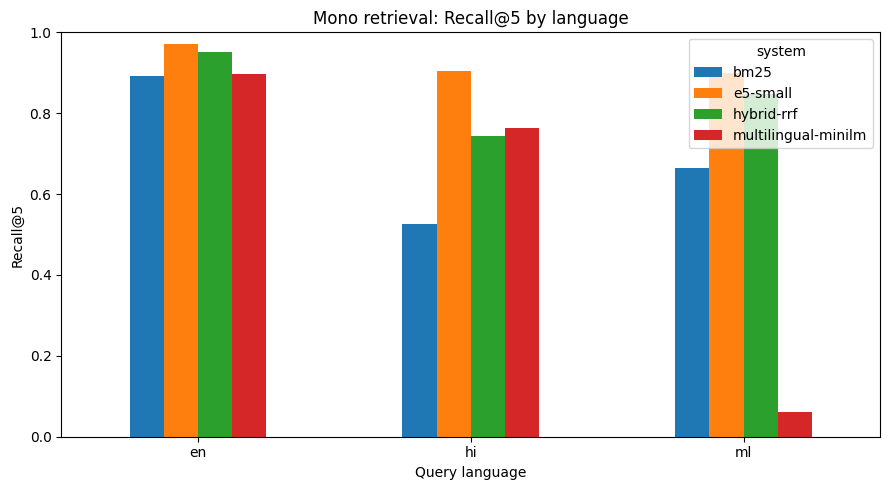

,system,query_lang,doc_lang,recall@1,recall@5,mrr
9,bm25,hi,en,0.0311,0.0456,0.0452
10,e5-small,hi,en,0.6833,0.8600,0.7620
11,multilingual-minilm,hi,en,0.5478,0.7356,0.6382
12,bm25,ml,en,0.0300,0.0444,0.0441
13,e5-small,ml,en,0.5833,0.7722,0.6735
14,multilingual-minilm,ml,en,0.0322,0.0722,0.0625
18,hybrid-rrf,hi,en,0.0800,0.2356,0.1877
19,hybrid-rrf,ml,en,0.0822,0.2211,0.1822


In [18]:
plot_df = mono.pivot(index="query_lang", columns="system", values="recall@5").reindex(["en","hi","ml"])
ax = plot_df.plot(kind="bar", figsize=(9,5))
ax.set_title("Mono retrieval: Recall@5 by language")
ax.set_xlabel("Query language")
ax.set_ylabel("Recall@5")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS / "recall_by_language.png", dpi=180)
plt.show()

cross = all_results[all_results["condition"] == "cross"]
display(cross[["system","query_lang","doc_lang","recall@1","recall@5","mrr"]].round(4))

## 8. Cost and efficiency

Report measured wall-clock latency from this run, not an assumed hardware-independent speed. The timings include embedding document encoding in this notebook, so they are an offline benchmark cost, not a production per-query latency. For a production estimate, precompute document embeddings and time query encoding plus search separately.

Record hardware and whether a GPU was available.

In [19]:
import torch
hardware = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "max_items": MAX_ITEMS if MAX_ITEMS is not None else "full",
    "model_load_seconds": model_load_seconds,
}
(RESULTS / "run_environment.json").write_text(json.dumps(hardware, indent=2), encoding="utf-8")
hardware

{'python': '3.13.16',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'torch': '2.11.0+cu130',
 'cuda_available': True,
 'gpu_name': 'Tesla T4',
 'max_items': 'full',
 'model_load_seconds': {'e5-small': 17.696347238000044,
  'multilingual-minilm': 8.197768623000002}}

## 9. Answer-quality evaluation: small human-review sample

Belebele includes multiple-choice questions and gold answers, but this notebook does not pretend that retrieval recall equals answer quality. Instead, it creates a review sheet for a manageable sample.

For each sampled query, a reviewer sees:
- the question and answer choices,
- the gold passage,
- the top retrieved passage from a selected system.

The reviewer records whether the retrieved passage contains enough evidence to answer the question. If you also want end-to-end answer correctness, the reviewer can record the selected answer after reading only the retrieved passage.

Use at least 20–30 questions per language if time permits. Ideally use two reviewers and report agreement; if only one reviewer is available, disclose that limitation.

In [20]:
def get_top_passage(system, condition, qlang, dlang, qid, rankings_dict):
    ranking = rankings_dict[(system, condition, qlang, dlang)]
    doc_idx = int(ranking[qid][0])
    return doc_idx, corpora[dlang][doc_idx]

In [21]:
def build_review_sheet(n_per_language=25, system="hybrid-rrf"):
    rows = []
    answer_key_rows = []
    rng = np.random.default_rng(SEED)
    for lang in ["en", "hi", "ml"]:
        count = min(n_per_language, len(raw[lang]))
        ids = sorted(rng.choice(len(raw[lang]), size=count, replace=False).tolist())
        for qid in ids:
            r = raw[lang].iloc[qid]
            doc_idx, retrieved = get_top_passage(system, "mono", lang, lang, qid, mitigation_rankings)
            rows.append({
                "language": lang, "query_id": qid,
                "question": r["question"],
                "choice_1": r["mc_answer1"], "choice_2": r["mc_answer2"],
                "choice_3": r["mc_answer3"], "choice_4": r["mc_answer4"],
                "retrieved_doc_id": doc_idx,
                "retrieved_passage": retrieved,
                "evidence_sufficient_0_or_1": "",
                "reviewer_answer_number_1_to_4": "",
                "reviewer_id": "",
                "notes": "",
            })
            answer_key_rows.append({
                "language": lang, "query_id": qid,
                "gold_answer_number": str(r["correct_answer_num"]),
                "gold_passage": r["passage"],
            })
    return pd.DataFrame(rows), pd.DataFrame(answer_key_rows)

review_sheet, answer_key = build_review_sheet(n_per_language=25)
review_sheet.to_csv(RESULTS / "answer_quality_review_template.csv", index=False)
# Keep this key private until reviewers have completed their assessments.
answer_key.to_csv(RESULTS / "answer_quality_private_key.csv", index=False)
display(review_sheet.head(3))


,language,query_id,question,choice_1,choice_2,choice_3,choice_4,retrieved_doc_id,retrieved_passage,evidence_sufficient_0_or_1,reviewer_answer_number_1_to_4,reviewer_id,notes
0,en,75,Which of the following was not a reason that a...,They provided access to meat,They helped graze the land,They offered companionship,They provided access to milk,43,Goats seem to have been first domesticated rou...,,,,
1,en,78,Which is the typical purpose of an experiment?,To eliminate one or more possible hypotheses,To figure out how the world works,To pose questions,To guide scientific research,45,Science’s main goal is to figure out the way t...,,,,
2,en,83,How long have humans been magnifying objects u...,For a thousand years,Since the late 16th century,For thousands of years,Since the early 16th century,47,Humans have been making and using lenses for m...,,,,


### 9.1 Summarize completed human review

After reviewers fill `answer_quality_review_template.csv`, save the completed file as `answer_quality_review_completed.csv` in `results/` and run this cell. Do not fill the template with guessed values.

In [22]:
completed_path = RESULTS / "answer_quality_review_completed.csv"
key_path = RESULTS / "answer_quality_private_key.csv"
if completed_path.exists() and key_path.exists():
    review = pd.read_csv(completed_path)
    key = pd.read_csv(key_path)
    review = review.merge(key[["language", "query_id", "gold_answer_number"]], on=["language", "query_id"], how="left")
    review["evidence_sufficient_0_or_1"] = pd.to_numeric(review["evidence_sufficient_0_or_1"], errors="coerce")
    review["reviewer_answer_number_1_to_4"] = pd.to_numeric(review["reviewer_answer_number_1_to_4"], errors="coerce")
    review["gold_answer_number"] = pd.to_numeric(review["gold_answer_number"], errors="coerce")
    review["answer_correct"] = (review["reviewer_answer_number_1_to_4"] == review["gold_answer_number"]).astype(float)
    human_summary = review.groupby("language").agg(
        n_reviewed=("query_id","count"),
        evidence_sufficient_rate=("evidence_sufficient_0_or_1","mean"),
        answer_accuracy_from_retrieved_passage=("answer_correct","mean"),
    ).reset_index()
    display(human_summary.round(3))
    human_summary.to_csv(RESULTS / "answer_quality_summary.csv", index=False)
else:
    print("Complete the review template first. Keep answer_quality_private_key.csv hidden from reviewers.")


Complete the review template first. Keep answer_quality_private_key.csv hidden from reviewers.


## 10. Bootstrap confidence intervals (optional but recommended)

This computes query-level bootstrap confidence intervals for Recall@5. It is useful because small score differences may be sampling noise. The interval is descriptive and does not replace a paired statistical test.

In [23]:
def bootstrap_recall5(rankings, gold, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    values = []
    n = len(gold)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        values.append(recall_at_k(rankings[idx], np.asarray(gold)[idx], 5))
    return float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5))

ci_rows = []
for key, rankings in {**baseline_rankings, **mitigation_rankings}.items():
    system, condition, qlang, dlang = key
    lo, hi = bootstrap_recall5(rankings, gold_indices[dlang])
    ci_rows.append({"system":system,"condition":condition,"query_lang":qlang,"doc_lang":dlang,
                    "recall@5_ci_low":lo,"recall@5_ci_high":hi})
cis = pd.DataFrame(ci_rows)
cis.to_csv(RESULTS / "recall5_bootstrap_ci.csv", index=False)
display(cis.round(4))

,system,condition,query_lang,doc_lang,recall@5_ci_low,recall@5_ci_high
0,bm25,mono,en,en,0.8700,0.9100
1,e5-small,mono,en,en,0.9622,0.9833
2,multilingual-minilm,mono,en,en,0.8789,0.9178
3,bm25,mono,hi,hi,0.4956,0.5589
4,e5-small,mono,hi,hi,0.8833,0.9222
5,multilingual-minilm,mono,hi,hi,0.7344,0.7900
6,bm25,mono,ml,ml,0.6333,0.6933
7,e5-small,mono,ml,ml,0.8778,0.9178
8,multilingual-minilm,mono,ml,ml,0.0456,0.0744
9,bm25,cross,hi,en,0.0322,0.0600


## 11. Export a compact results summary

This writes the key result tables and a plain-language summary skeleton. Complete the interpretation after reviewing the actual numbers and the human-review results.

In [24]:
summary_lines = [
    "# Multilingual Retrieval Fairness: Results",
    "",
    f"Aligned benchmark rows per language: {n}.",
    "",
    "## Mono Recall@5",
    mono[["system","query_lang","recall@5","mrr"]].to_markdown(index=False),
    "",
    "## Cross-language Recall@5",
    cross[["system","query_lang","doc_lang","recall@5","mrr"]].to_markdown(index=False),
    "",
    "## English-minus-language Recall@5 gaps",
    gaps.to_markdown(index=False) if len(gaps) else "Gap table unavailable.",
    "",
    "## Interpretation to complete",
    "- Identify which baseline has the largest Hindi and Malayalam gaps.",
    "- State whether Malayalam's gap is larger than Hindi's, supported by the table.",
    "- Compare hybrid gains against BM25 and dense E5.",
    "- Discuss measured runtime and the hardware recorded in run_environment.json.",
    "- Summarize human-review evidence sufficiency and answer accuracy, if completed.",
    "- State limitations: benchmark domain, one relevant passage per query, sample size, reviewer subjectivity, and hardware dependence.",
]
(RESULTS / "summary.md").write_text("\n".join(summary_lines), encoding="utf-8")
print("Saved outputs to", RESULTS.resolve())
print(sorted(p.name for p in RESULTS.iterdir()))

Saved outputs to /content/results
['all_retrieval_results.csv', 'answer_quality_private_key.csv', 'answer_quality_review_template.csv', 'baseline_results.csv', 'language_gaps.csv', 'mitigation_results.csv', 'recall5_bootstrap_ci.csv', 'recall_by_language.png', 'run_environment.json', 'summary.md']


## 12. Final checklist before submission

- [ ] Record the exact dataset split, row count and model IDs.
- [ ] Run the full dataset after the quick smoke test.
- [ ] Keep actual CSVs and environment metadata in `results/`.
- [ ] Complete the human answer-quality review and disclose the reviewer count.
- [ ] Interpret results from actual outputs; never invent or round scores to fit a desired conclusion.
- [ ] Include model/data limitations and dataset/model licences in the report/cards.
- [ ] Restart the kernel and run all cells from top to bottom to verify reproducibility.